PROJECT 2  Credit Card Fraud Detection

In [5]:
import numpy as np
import pandas as pd

#loading the dataset and checking the shape of the dataset
creditcard_df = pd.read_csv("creditcard.csv")

print("Dataset shape:", creditcard_df.shape)
display(creditcard_df.head())
display(creditcard_df.info())
display(creditcard_df.describe().T)

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

None

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


The data was loaded using pandas and cocnsisted of 31 variables with 101104 entries.All the entries are continuous variables

Missing values: 0
\nDuplicate rows: 1081
\nClass counts:


,count
Class,
Normal,284315
Fraud,492


Fraud percentage: 0.1727 %


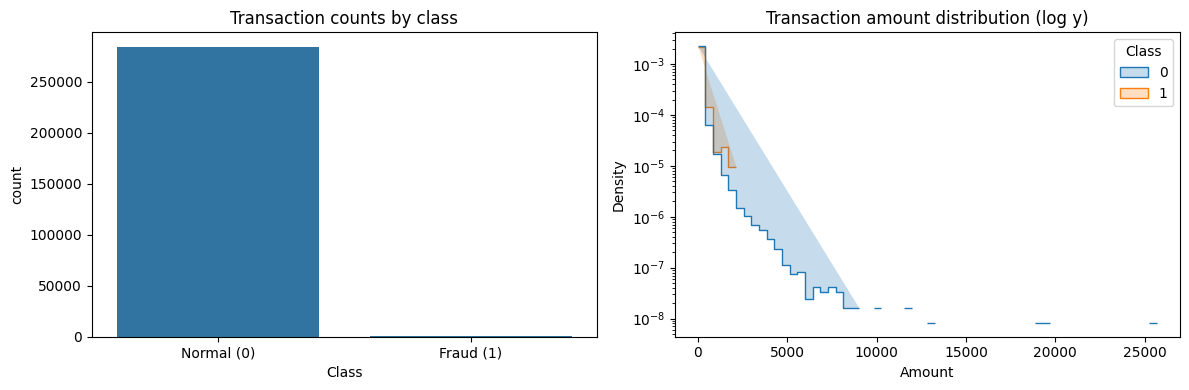

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

#Checking for missing values and duplicates rows
print("Missing values:", int(creditcard_df.isna().sum().sum()))
print("\\nDuplicate rows:", int(creditcard_df.duplicated().sum()))
print("\\nClass counts:")
display(creditcard_df["Class"].value_counts().rename(index={0:"Normal", 1:"Fraud"}))
print("Fraud percentage:", round(creditcard_df["Class"].mean() * 100, 4), "%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=creditcard_df, x="Class", ax=axes[0])
axes[0].set_title("Transaction counts by class")
axes[0].set_xticks([0,1], ["Normal (0)", "Fraud (1)"])
sns.histplot(data=creditcard_df, x="Amount", hue="Class", bins=60, log_scale=(False, True),
             element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Transaction amount distribution (log y)")
plt.tight_layout()
plt.show()


The data shows that their are no missing values.Their are a total of 1081 duplicate transactions,these are not going to be deleted since there is a possibility of legitmate transactions that are similar unless there is a unique identifier to separate them.

Normal (0): These are ordinary transactions that are not identified as fraudulent.Fraud (1):transactions identified as fraudulent.This indicates that there are more normal transactions as compared to fraudukent transactions.Fraud percenntage 0.1727% thus showimg a big class imbalance, which means that the model can easily identify normal transactions with with a very high accuracy but can easily fail to predict fradulent transactions.therefore accuracy alone will not be sufficient for the model

Amount                                                              \
          count        mean         std  min   25%    50%     75%       max   
Class                                                                         
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16   
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87   

           Time                                                       \
          count          mean           std    min      25%      50%   
Class                                                                  
0      284315.0  94838.202258  47484.015786    0.0  54230.0  84711.0   
1         492.0  80746.806911  47835.365138  406.0  41241.5  75568.5   

                           
            75%       max  
Class                      
0      139333.0  172792.0  
1      128483.0  170348.0

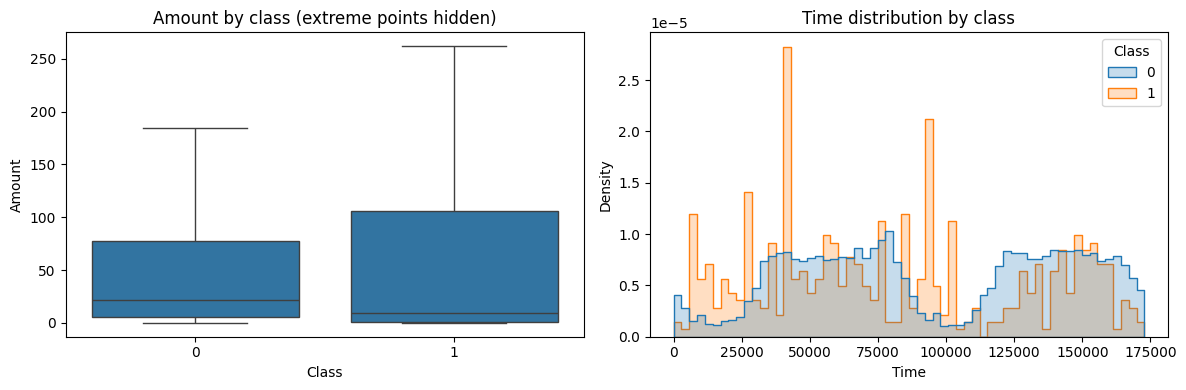

In [8]:
#exploring the selected variables
display(creditcard_df.groupby("Class")[["Amount", "Time"]].describe())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=creditcard_df, x="Class", y="Amount", showfliers=False, ax=axes[0])
axes[0].set_title("Amount by class (extreme points hidden)")
sns.histplot(data=creditcard_df, x="Time", hue="Class", bins=60, stat="density",
             common_norm=False, element="step", ax=axes[1])
axes[1].set_title("Time distribution by class")
plt.tight_layout()
plt.show()

The class counts demonstrate severe imbalance

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    classification_report, precision_recall_curve
)

#Preparing the modeelling data train/test split

#Setting the random state
RANDOM_STATE = 42
X = creditcard_df.drop(columns=["Class"])
y = creditcard_df["Class"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Fraud rate in training:", round(y_train.mean()*100, 4), "%")
print("Fraud rate in test:", round(y_test.mean()*100, 4), "%")

Training rows: 199364 | Test rows: 85443
Fraud rate in training: 0.1725 %
Fraud rate in test: 0.1732 %


In [15]:
#establishing a statistical outlier baseline using robust z-score
robust_scaler = RobustScaler()

X_train_robust = robust_scaler.fit_transform(X_train)
X_test_robust = robust_scaler.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

statistical_scores = np.max(
    np.abs(X_test_robust),
    axis=1
)

#Evaluating the statistical baseline
average_precision = average_precision_score(
    y_test,
    statistical_scores
)

roc_auc = roc_auc_score(
    y_test,
    statistical_scores
)

print("\nSTATISTICAL BASELINE PERFORMANCE")
print("--------------------------------")
print("Average Precision:", round(average_precision, 6))
print("ROC-AUC:", round(roc_auc, 6))

#Ranking the transactions
ranking = np.argsort(statistical_scores)[::-1]
total_fraud = int(y_test.sum())

print("\nTOP TRANSACTION RANKING")
print("-----------------------")

for k in [50, 100, 200]:
    top_indices = ranking[:k]
    fraud_found = int(
        y_test.iloc[top_indices].sum()
    )
    precision_k = fraud_found / k
    recall_k = fraud_found / total_fraud

    print("\nTop", k, "transactions")
    print("Fraud cases found:", fraud_found)
    print("Precision:", round(precision_k * 100, 2), "%")
    print("Recall:", round(recall_k * 100, 2), "%")

#Displaying the top 10 transactions
top_positions = ranking[:10]
top_transactions = X_test.iloc[
    top_positions
][["Time", "Amount"]].copy()
top_transactions["Actual_Class"] = (
    y_test.iloc[top_positions].values
)
top_transactions["Anomaly_Score"] = (
    statistical_scores[top_positions]
)
print("\nTOP 10 MOST UNUSUAL TRANSACTIONS")
display(top_transactions.reset_index(drop=True))



STATISTICAL BASELINE PERFORMANCE
--------------------------------
Average Precision: 0.022691
ROC-AUC: 0.920126

TOP TRANSACTION RANKING
-----------------------

Top 50 transactions
Fraud cases found: 2
Precision: 4.0 %
Recall: 1.35 %

Top 100 transactions
Fraud cases found: 3
Precision: 3.0 %
Recall: 2.03 %

Top 200 transactions
Fraud cases found: 5
Precision: 2.5 %
Recall: 3.38 %

TOP 10 MOST UNUSUAL TRANSACTIONS


,Time,Amount,Actual_Class,Anomaly_Score
0,42951.0,12910.93,0,179.436586
1,86570.0,102.00,0,172.354015
2,172273.0,10199.44,0,141.687874
3,145283.0,10000.00,0,138.911318
4,126271.0,175.00,0,122.875181
5,139181.0,0.76,0,119.804491
6,134033.0,1402.38,0,119.212368
7,134070.0,660.38,0,118.982963
8,140878.0,538.71,0,118.248131
9,141873.0,303.80,0,117.434541


Robustscaler was used since its less sensitive to extreme values.This approach provides a simple baseline against which the more advanced clustering and classification methods can be evaluated. However, it does not establish whether a transaction is genuinely fraudulent.
The statistical baseline is not very effective at prioritising fraud investigations even with the high ROC-AUC

In [19]:
#PART2
#Cluster based approach
cluster_scaler = StandardScaler()
X_train_scaled = cluster_scaler.fit_transform(X_train)
X_test_scaled = cluster_scaler.transform(X_test)

kmeans = MiniBatchKMeans(
    n_clusters=8,
    random_state=42,
    batch_size=4096,
    n_init=5
)
#Training the model
kmeans.fit(X_train_scaled)
cluster_distances = kmeans.transform(X_test_scaled)
cluster_scores = cluster_distances.min(axis=1)
kmeans_scores = cluster_scores
print("\n========== K-MEANS RESULTS ==========")
print(
    "Average Precision:",
    round(average_precision_score(y_test, kmeans_scores), 6)
)
print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, kmeans_scores), 6)
)
#Classification approach - Logistic regression
#Creating the classification model
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42,
    solver="liblinear"
)
#Training using the actual fraud labels
logistic_model.fit(X_train_scaled, y_train)

#Predicting probability of fraud for each test transaction
classification_scores = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

#Classifying using a probability threshold of 0.50
classification_predictions = (
    classification_scores >= 0.50
).astype(int)
print("\n========== LOGISTIC REGRESSION RESULTS ==========")

print(
    "Average Precision:",
    round(average_precision_score(y_test, classification_scores), 6)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, classification_scores), 6)
)

print(
    "Precision:",
    round(precision_score(
        y_test, classification_predictions, zero_division=0
    ), 6)
)
print(
    "Recall:",
    round(recall_score(
        y_test, classification_predictions, zero_division=0
    ), 6)
)
print(
    "F1-score:",
    round(f1_score(
        y_test, classification_predictions, zero_division=0
    ), 6)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, classification_predictions))

#Comparing the three approaches
models = {
    "Statistical Baseline": statistical_scores,
    "MiniBatch K-Means": kmeans_scores,
    "Logistic Regression": classification_scores
}

comparison_results = []
for model_name, scores in models.items():

    comparison_results.append({
        "Method": model_name,

        "Average Precision": average_precision_score(
            y_test, scores
        ),

        "ROC-AUC": roc_auc_score(
            y_test, scores
        )
    })

comparison_table = pd.DataFrame(comparison_results)
print("\n========== MODEL COMPARISON ==========")
print(
    comparison_table.to_string(
        index=False,
        formatters={
            "Average Precision": "{:.6f}".format,
            "ROC-AUC": "{:.6f}".format
        }
    )
)
#TOP-K FRAUD DETECTION COMPARISON
print("\n========== TOP-K COMPARISON ==========")
for k in [50, 100, 200]:

    print(f"\nTOP {k} TRANSACTIONS")

    for model_name, scores in models.items():

        top_indices = np.argsort(scores)[::-1][:k]

        fraud_found = int(
            y_test.iloc[top_indices].sum()
        )

        precision_at_k = fraud_found / k

        recall_at_k = fraud_found / int(y_test.sum())

        print(
            model_name,
            "| Fraud found:", fraud_found,
            "| Precision:", round(precision_at_k * 100, 2), "%",
            "| Recall:", round(recall_at_k * 100, 2), "%"
        )



========== K-MEANS RESULTS ==========
Average Precision: 0.154758
ROC-AUC: 0.949825

========== LOGISTIC REGRESSION RESULTS ==========
Average Precision: 0.704039
ROC-AUC: 0.968024
Precision: 0.066976
Recall: 0.878378
F1-score: 0.124461

Confusion Matrix:
[[83484  1811]
 [   18   130]]

========== MODEL COMPARISON ==========
              Method Average Precision  ROC-AUC
Statistical Baseline          0.022691 0.920126
   MiniBatch K-Means          0.154758 0.949825
 Logistic Regression          0.704039 0.968024

========== TOP-K COMPARISON ==========

TOP 50 TRANSACTIONS
Statistical Baseline | Fraud found: 2 | Precision: 4.0 % | Recall: 1.35 %
MiniBatch K-Means | Fraud found: 21 | Precision: 42.0 % | Recall: 14.19 %
Logistic Regression | Fraud found: 41 | Precision: 82.0 % | Recall: 27.7 %

TOP 100 TRANSACTIONS
Statistical Baseline | Fraud found: 3 | Precision: 3.0 % | Recall: 2.03 %
MiniBatch K-Means | Fraud found: 31 | Precision: 31.0 % | Recall: 20.95 %
Logistic Regression | Frau

1. Analysis of K-Means clustering results

MiniBatch K-Means was selected because it is suitable for relatively large datasets

In [11]:
def ranking_metrics(y_true, scores, model_name, k_values=(50, 100, 200)):
    result = {
        "Model": model_name,
        "Average Precision": average_precision_score(y_true, scores),
        "ROC-AUC": roc_auc_score(y_true, scores)
    }
    y_array = np.asarray(y_true)
    score_array = np.asarray(scores)
    order = np.argsort(score_array)[::-1]
    total_fraud = int(y_array.sum())

    for k in k_values:
        top_idx = order[:k]
        tp = int(y_array[top_idx].sum())
        result[f"Precision@{k}"] = tp / k
        result[f"Recall@{k}"] = tp / total_fraud if total_fraud else np.nan
    return result